In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


path=r"C:\Users\user\Downloads\projects\credit risk analysis\accepted_2007_to_2018q4.csv\accepted_2007_to_2018Q4.csv"

USE_COLS = [
    "id", "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "issue_d", "purpose",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "addr_state", "dti",
    "earliest_cr_line", "fico_range_low", "fico_range_high", "delinq_2yrs",
    "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "mort_acc", "pub_rec_bankruptcies",
    "loan_status", "total_pymnt", "total_rec_prncp", "recoveries",
]



df = pd.read_csv(path, usecols=USE_COLS, low_memory=False)

In [2]:
print(df.shape)
print("----------------------")
print(df.head())

(2260701, 31)
----------------------
         id  loan_amnt        term  int_rate  installment grade sub_grade  \
0  68407277     3600.0   36 months     13.99       123.03     C        C4   
1  68355089    24700.0   36 months     11.99       820.28     C        C1   
2  68341763    20000.0   60 months     10.78       432.66     B        B4   
3  66310712    35000.0   60 months     14.85       829.90     C        C5   
4  68476807    10400.0   60 months     22.45       289.91     F        F1   

  emp_length home_ownership  annual_inc verification_status   issue_d  \
0  10+ years       MORTGAGE     55000.0        Not Verified  Dec-2015   
1  10+ years       MORTGAGE     65000.0        Not Verified  Dec-2015   
2  10+ years       MORTGAGE     63000.0        Not Verified  Dec-2015   
3  10+ years       MORTGAGE    110000.0     Source Verified  Dec-2015   
4    3 years       MORTGAGE    104433.0     Source Verified  Dec-2015   

  loan_status             purpose addr_state    dti  delinq_2

# Data cleaning

In [3]:
df = df[pd.to_numeric(df["id"], errors="coerce").notna()].copy()
print(len(df))

2260668


In [4]:
print(df["loan_status"].value_counts())

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64


In [5]:
status_map = {
    "Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1,
    "Does not meet the credit policy. Status:Fully Paid": 0,
    "Does not meet the credit policy. Status:Charged Off": 1,
}
df = df[df["loan_status"].isin(status_map)].copy()
df["default"] = df["loan_status"].map(status_map).astype("int8")

In [6]:
df.head()

,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,total_pymnt,total_rec_prncp,recoveries,mort_acc,pub_rec_bankruptcies,default
0,68407277,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,debt_consolidation,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,7.0,0.0,2765.0,29.7,13.0,4421.723917,3600.0,0.0,1.0,0.0,0
1,68355089,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,small_business,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,22.0,0.0,21470.0,19.2,38.0,25679.660000,24700.0,0.0,4.0,0.0,0
2,68341763,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,home_improvement,IL,10.78,0.0,Aug-2000,695.0,699.0,0.0,6.0,0.0,7869.0,56.2,18.0,22705.924294,20000.0,0.0,5.0,0.0,0
4,68476807,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Source Verified,Dec-2015,Fully Paid,major_purchase,PA,25.37,1.0,Jun-1998,695.0,699.0,3.0,12.0,0.0,21929.0,64.5,35.0,11740.500000,10400.0,0.0,6.0,0.0,0
5,68426831,11950.0,36 months,13.44,405.18,C,C3,4 years,RENT,34000.0,Source Verified,Dec-2015,Fully Paid,debt_consolidation,GA,10.20,0.0,Oct-1987,690.0,694.0,0.0,5.0,0.0,8822.0,68.4,6.0,13708.948530,11950.0,0.0,0.0,0.0,0


In [7]:
df["id"] = df["id"].astype("int64")
df["term"] = df["term"].astype(str).str.extract(r"(\d+)")[0].astype(int)

for c in ["int_rate", "revol_util"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace("%", "", regex=False), errors="coerce")

df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")

In [8]:
df["emp_length_num"] = df["emp_length"].str.extract(r"(\d+)")[0].astype(float)
df.loc[df["emp_length"] == "< 1 year", "emp_length_num"] = 0

df["issue_year"] = df["issue_d"].dt.year
df["credit_history_years"] = (df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"].replace(0, np.nan)
df["installment_to_income"] = (df["installment"] * 12) / df["annual_inc"].replace(0, np.nan)

df = df.drop(columns=["emp_length", "fico_range_low", "fico_range_high"])

In [9]:
df.head()

,id,loan_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,total_pymnt,total_rec_prncp,recoveries,mort_acc,pub_rec_bankruptcies,default,emp_length_num,issue_year,credit_history_years,fico_avg,loan_to_income,installment_to_income
0,68407277,3600.0,36,13.99,123.03,C,C4,MORTGAGE,55000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,PA,5.91,0.0,2003-08-01,1.0,7.0,0.0,2765.0,29.7,13.0,4421.723917,3600.0,0.0,1.0,0.0,0,10.0,2015,12.334018,677.0,0.065455,0.026843
1,68355089,24700.0,36,11.99,820.28,C,C1,MORTGAGE,65000.0,Not Verified,2015-12-01,Fully Paid,small_business,SD,16.06,1.0,1999-12-01,4.0,22.0,0.0,21470.0,19.2,38.0,25679.660000,24700.0,0.0,4.0,0.0,0,10.0,2015,16.000000,717.0,0.380000,0.151436
2,68341763,20000.0,60,10.78,432.66,B,B4,MORTGAGE,63000.0,Not Verified,2015-12-01,Fully Paid,home_improvement,IL,10.78,0.0,2000-08-01,0.0,6.0,0.0,7869.0,56.2,18.0,22705.924294,20000.0,0.0,5.0,0.0,0,10.0,2015,15.331964,697.0,0.317460,0.082411
4,68476807,10400.0,60,22.45,289.91,F,F1,MORTGAGE,104433.0,Source Verified,2015-12-01,Fully Paid,major_purchase,PA,25.37,1.0,1998-06-01,3.0,12.0,0.0,21929.0,64.5,35.0,11740.500000,10400.0,0.0,6.0,0.0,0,3.0,2015,17.500342,697.0,0.099585,0.033312
5,68426831,11950.0,36,13.44,405.18,C,C3,RENT,34000.0,Source Verified,2015-12-01,Fully Paid,debt_consolidation,GA,10.20,0.0,1987-10-01,0.0,5.0,0.0,8822.0,68.4,6.0,13708.948530,11950.0,0.0,0.0,0.0,0,4.0,2015,28.167009,692.0,0.351471,0.143005


In [10]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).round(2)
print(missing[missing > 0])

emp_length_num           5.83
mort_acc                 3.71
pub_rec_bankruptcies     0.10
revol_util               0.07
dti                      0.03
installment_to_income    0.03
loan_to_income           0.03
dtype: float64


In [11]:
num_cols = df.select_dtypes(include="number").columns.drop(["default", "id"])
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# we exclude id and default because when it involved it will bw pointless for analysis

cat_cols = df.select_dtypes(include="object").columns
df[cat_cols] = df[cat_cols].fillna("Unknown")


for c in ["annual_inc", "revol_bal"]:
    df[c] = df[c].clip(upper=df[c].quantile(0.995))

# 3 standart sama uzaqliqdaki datalari daxil etmeyecek 

In [12]:
print("Dublikat id:", df["id"].duplicated().sum())
print("Qalan boş qiymət:", df.isna().sum().sum())
df.describe().T.round(2)

Dublikat id: 0
Qalan boş qiymət: 29


,count,mean,min,25%,50%,75%,max,std
id,1348099.0,56232400.550466,54734.0,19726827.0,57674179.0,84505814.5,145636374.0,38405660.294818
loan_amnt,1348099.0,14408.998913,500.0,7975.0,12000.0,20000.0,40000.0,8716.137925
term,1348099.0,41.78402,36.0,36.0,36.0,36.0,60.0,10.264584
int_rate,1348099.0,13.241562,5.31,9.75,12.74,15.99,30.99,4.765685
installment,1348099.0,437.777843,4.93,248.28,375.04,580.22,1719.83,261.49719
annual_inc,1348099.0,75113.824898,0.0,45750.0,65000.0,90000.0,325000.0,44839.649801
issue_d,1348099,2015-06-02 04:04:23.848871936,2007-06-01 00:00:00,2014-07-01 00:00:00,2015-08-01 00:00:00,2016-07-01 00:00:00,2018-12-01 00:00:00,NaN
dti,1348099.0,18.274069,-1.0,11.79,17.61,24.05,999.0,11.153953
delinq_2yrs,1348099.0,0.317626,0.0,0.0,0.0,0.0,39.0,0.877736
earliest_cr_line,1348070,1999-03-02 18:43:02.604167040,1934-04-01 00:00:00,1995-04-01 00:00:00,2000-08-01 00:00:00,2004-06-01 00:00:00,2015-10-01 00:00:00,NaN


In [14]:
overall = df["default"].mean() * 100
print(overall)

19.980728418313493


In [15]:
t = df.groupby("grade").agg(
    loans=("id", "count"),
    defaults=("default", "sum"),
    default_rate=("default", "mean"),
    avg_int_rate=("int_rate", "mean"),
    avg_loan=("loan_amnt", "mean"),
    avg_fico=("fico_avg", "mean"),
)

t["default_rate"] = t["default_rate"] * 100
t["lift"] = t["default_rate"] / overall
t.round(2)

,loans,defaults,default_rate,avg_int_rate,avg_loan,avg_fico,lift
grade,,,,,,,
A,235193,14214,6.04,7.11,13888.99,729.53,0.30
B,393102,52661,13.40,10.68,13233.33,699.14,0.67
C,382323,85805,22.44,14.02,14179.87,689.98,1.12
D,201657,61264,30.38,17.71,15248.91,685.26,1.52
E,94192,36199,38.43,21.11,17566.09,683.96,1.92
F,32306,14585,45.15,24.88,19032.59,681.79,2.26
G,9326,4632,49.67,27.54,20407.61,680.19,2.49


In [16]:
t = df.groupby("term").agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
    avg_int_rate=("int_rate", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate,avg_int_rate
term,,,
36,1023206,16.02,12.12
60,324893,32.45,16.77


In [20]:
t = df.groupby("home_ownership").agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t[t["loans"] > 1000].round(2)

,loans,default_rate
home_ownership,,
MORTGAGE,666852,17.23
OWN,145027,20.63
RENT,535699,23.23


In [21]:
t = df.groupby("verification_status").agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate
verification_status,,
Not Verified,407541,14.74
Source Verified,521579,20.96
Verified,418979,23.86


In [22]:
t = df.groupby("addr_state").agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t[t["loans"] > 5000].sort_values("default_rate", ascending=False).head(10).round(2)

,loans,default_rate
addr_state,,
MS,6595,26.11
AR,10062,24.11
AL,16645,23.63
OK,12298,23.47
LA,15524,23.18
NY,110097,22.05
NV,20296,21.97
FL,95843,21.50
IN,21726,21.43


In [23]:
t = df.groupby("issue_year").agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
    avg_int_rate=("int_rate", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate,avg_int_rate
issue_year,,,
2007,603,26.20,11.83
2008,2393,20.73,12.06
2009,5281,13.69,12.44
2010,12537,14.01,11.99
2011,21721,15.18,12.22
2012,53367,16.20,13.64
2013,134804,15.60,14.53
2014,223103,18.45,13.66
2015,375546,20.19,12.39


In [24]:
df["fico_band"] = pd.cut(
    df["fico_avg"],
    bins=[0, 660, 700, 740, 780, 850],
    labels=["<660", "660-700", "700-740", "740-780", "780+"],
)

t = df.groupby("fico_band", observed=True).agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate
fico_band,,
<660,489,30.88
660-700,822224,23.60
700-740,380014,16.08
740-780,107034,10.57
780+,38338,7.11


In [25]:
df["dti_band"] = pd.cut(df["dti"], bins=[-1, 10, 20, 30, 40, 1000],
                        labels=["0-10", "10-20", "20-30", "30-40", "40+"])

t = df.groupby("dti_band", observed=True).agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate
dti_band,,
0-10,247033,14.92
10-20,563722,17.87
20-30,409035,23.06
30-40,121541,29.10
40+,6766,30.55


In [26]:
df["income_band"] = pd.cut(df["annual_inc"], bins=[0, 30000, 50000, 75000, 100000, 150000, 10**9],
                           labels=["<30k", "30-50k", "50-75k", "75-100k", "100-150k", "150k+"])

t = df.groupby("income_band", observed=True).agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

,loans,default_rate
income_band,,
<30k,99407,24.38
30-50k,334459,22.50
50-75k,412620,20.50
75-100k,250780,18.27
100-150k,179178,16.19
150k+,71294,14.62


In [27]:
t = df.groupby(["grade", "term"]).agg(
    loans=("id", "count"),
    default_rate=("default", "mean"),
)
t["default_rate"] = t["default_rate"] * 100
t.round(2)

loans  default_rate
grade term                      
A     36    228903          5.92
      60      6290         10.60
B     36    345272         12.76
      60     47830         18.01
C     36    276712         20.50
      60    105611         27.53
D     36    126683         26.89
      60     74974         36.27
E     36     36468         32.63
      60     57724         42.09
F     36      7485         38.06
      60     24821         47.28
G     36      1683         46.64
      60      7643         50.33

In [28]:
pd.pivot_table(df, index="grade", columns="term", values="default", aggfunc="mean").mul(100).round(1)

term,36,60
grade,,
A,5.9,10.6
B,12.8,18.0
C,20.5,27.5
D,26.9,36.3
E,32.6,42.1
F,38.1,47.3
G,46.6,50.3


In [29]:
df.head()

,id,loan_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,total_pymnt,total_rec_prncp,recoveries,mort_acc,pub_rec_bankruptcies,default,emp_length_num,issue_year,credit_history_years,fico_avg,loan_to_income,installment_to_income,fico_band,dti_band,income_band
0,68407277,3600.0,36,13.99,123.03,C,C4,MORTGAGE,55000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,PA,5.91,0.0,2003-08-01,1.0,7.0,0.0,2765.0,29.7,13.0,4421.723917,3600.0,0.0,1.0,0.0,0,10.0,2015,12.334018,677.0,0.065455,0.026843,660-700,0-10,50-75k
1,68355089,24700.0,36,11.99,820.28,C,C1,MORTGAGE,65000.0,Not Verified,2015-12-01,Fully Paid,small_business,SD,16.06,1.0,1999-12-01,4.0,22.0,0.0,21470.0,19.2,38.0,25679.660000,24700.0,0.0,4.0,0.0,0,10.0,2015,16.000000,717.0,0.380000,0.151436,700-740,10-20,50-75k
2,68341763,20000.0,60,10.78,432.66,B,B4,MORTGAGE,63000.0,Not Verified,2015-12-01,Fully Paid,home_improvement,IL,10.78,0.0,2000-08-01,0.0,6.0,0.0,7869.0,56.2,18.0,22705.924294,20000.0,0.0,5.0,0.0,0,10.0,2015,15.331964,697.0,0.317460,0.082411,660-700,10-20,50-75k
4,68476807,10400.0,60,22.45,289.91,F,F1,MORTGAGE,104433.0,Source Verified,2015-12-01,Fully Paid,major_purchase,PA,25.37,1.0,1998-06-01,3.0,12.0,0.0,21929.0,64.5,35.0,11740.500000,10400.0,0.0,6.0,0.0,0,3.0,2015,17.500342,697.0,0.099585,0.033312,660-700,20-30,100-150k
5,68426831,11950.0,36,13.44,405.18,C,C3,RENT,34000.0,Source Verified,2015-12-01,Fully Paid,debt_consolidation,GA,10.20,0.0,1987-10-01,0.0,5.0,0.0,8822.0,68.4,6.0,13708.948530,11950.0,0.0,0.0,0.0,0,4.0,2015,28.167009,692.0,0.351471,0.143005,660-700,10-20,30-50k


In [32]:
baglanma_analizi = (
    df.assign(
        close_year=lambda x: (x["issue_d"] + pd.to_timedelta(x["term"] * 30.44, unit="D")).dt.year
    )
    .groupby(["close_year", "default"], observed=True)
    .size()
    .unstack(fill_value=0)
)

baglanma_analizi.columns = ["Uğurla Bağlananlar (Fully Paid)", "Batanlar (Charged Off / Default)"]

print(baglanma_analizi)


            Uğurla Bağlananlar (Fully Paid)  Batanlar (Charged Off / Default)
close_year                                                                   
2010                                    666                               242
2011                                   1676                               412
2012                                   5128                               815
2013                                   8440                              1003
2014                                  13522                              1688
2015                                  38417                              6376
2016                                 104316                             15765
2017                                 157076                             26983
2018                                 265814                             50495
2019                                 208628                             61734
2020                                 170622                     

In [33]:
# 2016 ilden sornraki bir cox kredit helede baglanmayib  ona gore 2015 asagi iller goturek
d = df[df["issue_year"].between(2009, 2015)].copy()

d["unpaid_principal"] = (d["loan_amnt"] - d["total_rec_prncp"]).clip(lower=0)

bad = d[d["default"] == 1]

print("Kredit sayı:", len(d), "| Default sayı:", len(bad))

Kredit sayı: 826359 | Default sayı: 152411


In [34]:
PD = d["default"].mean()
EAD = bad["unpaid_principal"].mean()                                   
LGD = 1 - bad["recoveries"].sum() / bad["unpaid_principal"].sum()    

EL_per_loan = PD * LGD * EAD
EL_total = EL_per_loan * len(d)
volume = d["loan_amnt"].sum()

print(f"PD:  {PD:.2%}")
print(f"LGD: {LGD:.2%}")
print(f"EAD (orta, default olan kreditdə): {EAD:,.0f}$")
print(f"Bir kreditə düşən EL: {EL_per_loan:,.0f}$")
print(f"Portfelin ümumi EL: {EL_total:,.0f}$")
print(f"EL rate (EL / verilən həcm): {EL_total / volume:.2%}")

actual = bad["unpaid_principal"].sum() - bad["recoveries"].sum()
print(f"Faktiki itki: {actual:,.0f}$")

PD:  18.44%
LGD: 87.62%
EAD (orta, default olan kreditdə): 10,339$
Bir kreditə düşən EL: 1,671$
Portfelin ümumi EL: 1,380,703,524$
EL rate (EL / verilən həcm): 11.60%
Faktiki itki: 1,380,703,524$


In [35]:
a = d.groupby("grade").agg(
    loans=("id", "count"),
    volume=("loan_amnt", "sum"),
    defaults=("default", "sum"),
)

b = bad.groupby("grade").agg(
    unpaid=("unpaid_principal", "sum"),
    recov=("recoveries", "sum"),
    EAD_avg=("unpaid_principal", "mean"),
)

t = a.join(b)
t["PD_%"] = t["defaults"] / t["loans"] * 100
t["LGD_%"] = (1 - t["recov"] / t["unpaid"]) * 100
t["EL_$"] = (t["PD_%"] / 100) * (t["LGD_%"] / 100) * t["EAD_avg"] * t["loans"]
t["EL_rate_%"] = t["EL_$"] / t["volume"] * 100
t["EL_share_%"] = t["EL_$"] / t["EL_$"].sum() * 100
t["actual_loss_$"] = t["unpaid"] - t["recov"]

t[["loans", "PD_%", "LGD_%", "EAD_avg", "EL_$", "EL_rate_%", "EL_share_%", "actual_loss_$"]].round(2)

,loans,PD_%,LGD_%,EAD_avg,EL_$,EL_rate_%,EL_share_%,actual_loss_$
grade,,,,,,,,
A,146132,5.57,87.57,6933.77,4.941871e+07,2.42,3.58,4.941871e+07
B,241173,12.04,87.81,7783.60,1.984152e+08,6.19,14.37,1.984152e+08
C,225142,20.37,87.67,9207.84,3.702480e+08,11.74,26.82,3.702480e+08
D,126175,28.13,87.69,10898.59,3.392296e+08,17.90,24.57,3.392296e+08
E,62022,36.75,87.59,13599.85,2.714912e+08,24.68,19.66,2.714912e+08
F,20777,42.30,87.20,15434.13,1.182696e+08,29.94,8.57,1.182696e+08
G,4938,46.60,87.12,16776.61,3.363116e+07,32.83,2.44,3.363116e+07


In [36]:
a = d.groupby("term").agg(loans=("id", "count"), volume=("loan_amnt", "sum"), defaults=("default", "sum"))
b = bad.groupby("term").agg(unpaid=("unpaid_principal", "sum"), recov=("recoveries", "sum"), EAD_avg=("unpaid_principal", "mean"))

t = a.join(b)
t["PD_%"] = t["defaults"] / t["loans"] * 100
t["LGD_%"] = (1 - t["recov"] / t["unpaid"]) * 100
t["EL_$"] = (t["PD_%"] / 100) * (t["LGD_%"] / 100) * t["EAD_avg"] * t["loans"]
t["EL_rate_%"] = t["EL_$"] / t["volume"] * 100
t.round(2)

,loans,volume,defaults,unpaid,recov,EAD_avg,PD_%,LGD_%,EL_$,EL_rate_%
term,,,,,,,,,,
36,618026,7.724749e+09,85950,6.060605e+08,7.800298e+07,7051.32,13.91,87.13,5.280576e+08,6.84
60,208333,4.173971e+09,66461,9.697124e+08,1.170665e+08,14590.70,31.90,87.93,8.526460e+08,20.43


In [37]:
a = d.groupby(["grade", "term"]).agg(loans=("id", "count"), volume=("loan_amnt", "sum"), defaults=("default", "sum"))
b = bad.groupby(["grade", "term"]).agg(unpaid=("unpaid_principal", "sum"), recov=("recoveries", "sum"), EAD_avg=("unpaid_principal", "mean"))

t = a.join(b)
t["PD_%"] = t["defaults"] / t["loans"] * 100
t["LGD_%"] = (1 - t["recov"] / t["unpaid"]) * 100
t["EL_$"] = (t["PD_%"] / 100) * (t["LGD_%"] / 100) * t["EAD_avg"] * t["loans"]
t["EL_rate_%"] = t["EL_$"] / t["volume"] * 100

t[["loans", "PD_%", "LGD_%", "EAD_avg", "EL_rate_%"]].round(2)

loans   PD_%  LGD_%   EAD_avg  EL_rate_%
grade term                                           
A     36    142610   5.48  87.42   6736.61       2.32
      60      3522   9.34  89.61  11614.16       5.44
B     36    211275  11.19  87.42   6583.36       5.20
      60     29898  18.01  88.68  13054.93      10.60
C     36    161681  17.92  87.11   6882.12       9.05
      60     63461  26.62  88.17  13195.63      15.91
D     36     76145  23.33  86.98   7605.52      13.09
      60     50030  35.44  88.07  14198.53      22.23
E     36     21451  28.56  86.71   8249.92      17.06
      60     40571  41.08  87.76  15566.79      27.00
F     36      4302  32.80  85.81   7597.85      21.36
      60     16475  44.78  87.32  16932.97      30.99
G     36       562  39.15  86.45   9156.50      23.78
      60      4376  47.55  87.16  17582.19      33.53

In [40]:
# qazancin ve faizin analizi hansi coxdu faiz loss oturmu ?
r = d.groupby("grade").agg(avg_int_rate=("int_rate", "mean"))
r["EL_rate_%"] = t.groupby("grade")["EL_$"].sum() / d.groupby("grade")["loan_amnt"].sum() * 100
r["spread"] = r["avg_int_rate"] - r["EL_rate_%"]
r.round(2)

,avg_int_rate,EL_rate_%,spread
grade,,,
A,7.23,2.42,4.82
B,10.86,6.19,4.67
C,14.03,11.74,2.29
D,17.23,17.90,-0.67
E,19.98,24.68,-4.70
F,23.63,29.94,-6.31
G,25.74,32.83,-7.09


# Visualition

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, RED, GREEN, GREY = "#1f4e79", "#c0392b", "#2a9d8f", "#7f8c8d"

In [43]:
d = df[df["issue_year"].between(2009, 2015)].copy()

d["unpaid_principal"] = (d["loan_amnt"] - d["total_rec_prncp"]).clip(lower=0)   
d["loss"] = np.where(d["default"] == 1,
                     (d["unpaid_principal"] - d["recoveries"]).clip(lower=0), 0) 
d["profit"] = d["total_pymnt"] - d["loan_amnt"]

bad = d[d["default"] == 1]
overall = d["default"].mean() * 100

d["fico_band"] = pd.cut(d["fico_avg"], [0, 660, 700, 740, 780, 850],
                        labels=["<660", "660-700", "700-740", "740-780", "780+"])
d["dti_band"] = pd.cut(d["dti"], [-1, 10, 20, 30, 40, 1000],
                       labels=["0-10", "10-20", "20-30", "30-40", "40+"])
d["income_band"] = pd.cut(d["annual_inc"], [0, 30e3, 50e3, 75e3, 100e3, 150e3, 1e9],
                          labels=["<30k", "30-50k", "50-75k", "75-100k", "100-150k", "150k+"])

print(f"2009-2015: {len(d):,} kredit | default rate: {overall:.2f}%")

2009-2015: 826,359 kredit | default rate: 18.44%


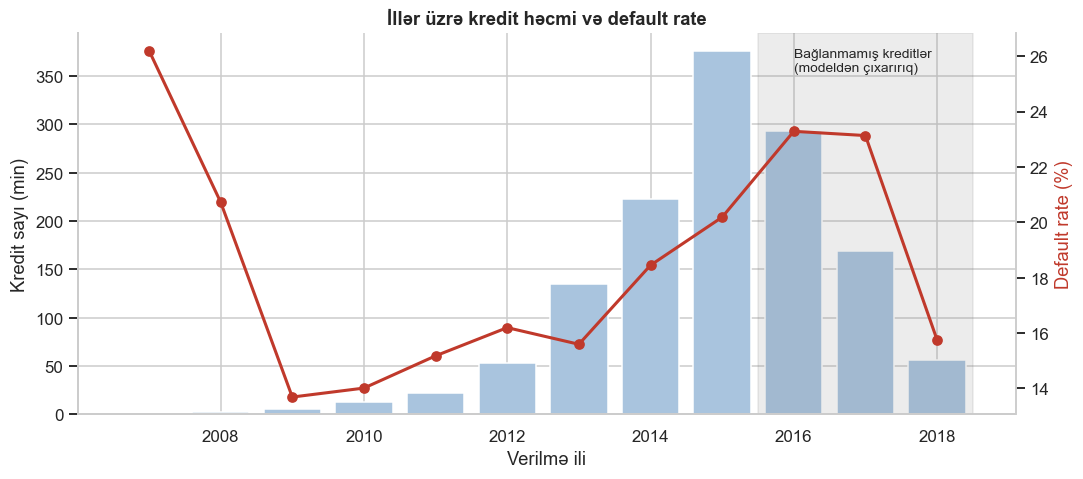

In [44]:
v = df.groupby("issue_year").agg(loans=("id", "count"), rate=("default", "mean"))
v["rate"] = v["rate"] * 100

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(v.index, v["loans"] / 1000, color="#a9c4de")
ax1.set_ylabel("Kredit sayı (min)")
ax1.set_xlabel("Verilmə ili")

ax2 = ax1.twinx()
ax2.plot(v.index, v["rate"], color=RED, marker="o", lw=2)
ax2.set_ylabel("Default rate (%)", color=RED)
ax2.grid(False)
ax2.spines["right"].set_visible(True)

ax1.axvspan(2015.5, v.index.max() + 0.5, color="grey", alpha=0.15)
ax1.text(2016, ax1.get_ylim()[1] * 0.9, "Bağlanmamış kreditlər\n(modeldən çıxarırıq)", fontsize=9)

plt.title("İllər üzrə kredit həcmi və default rate")
plt.show()

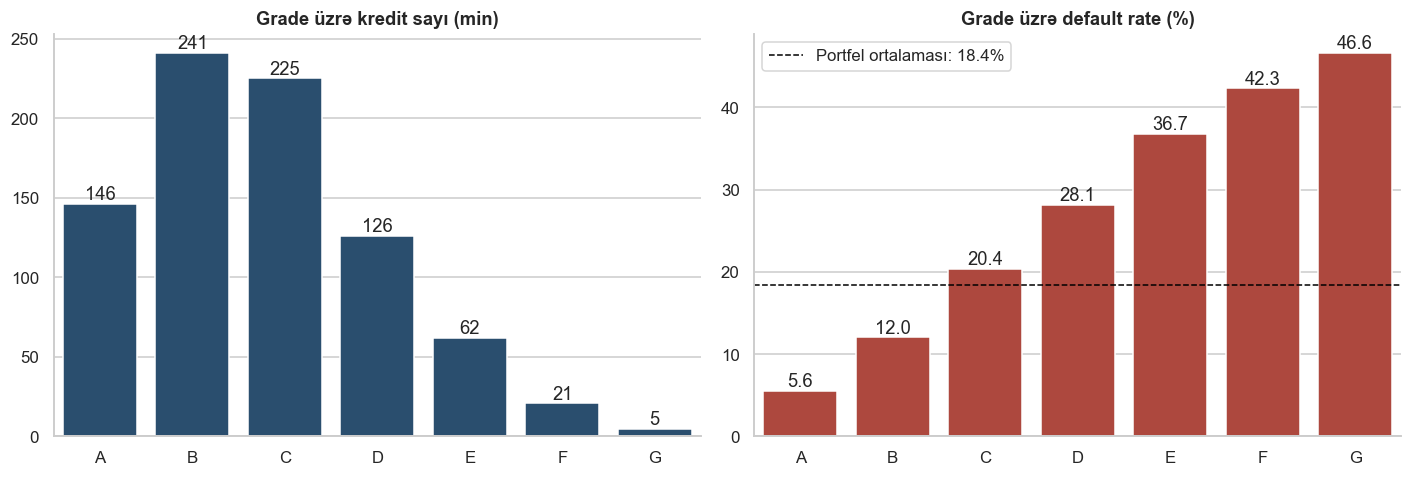

In [45]:
g = d.groupby("grade").agg(loans=("id", "count"), rate=("default", "mean"))
g["rate"] = g["rate"] * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(x=g.index, y=g["loans"] / 1000, color=BLUE, ax=ax[0])
ax[0].bar_label(ax[0].containers[0], fmt="%.0f")
ax[0].set_title("Grade üzrə kredit sayı (min)")
ax[0].set_xlabel("")
ax[0].set_ylabel("")

sns.barplot(x=g.index, y=g["rate"], color=RED, ax=ax[1])
ax[1].bar_label(ax[1].containers[0], fmt="%.1f")
ax[1].axhline(overall, color="black", ls="--", lw=1, label=f"Portfel ortalaması: {overall:.1f}%")
ax[1].set_title("Grade üzrə default rate (%)")
ax[1].set_xlabel("")
ax[1].set_ylabel("")
ax[1].legend()

plt.tight_layout()
plt.show()

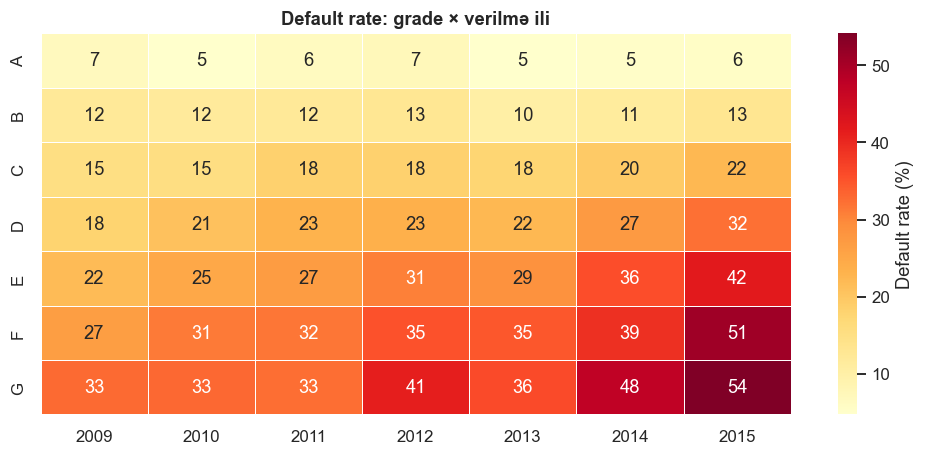

In [46]:
pv = d.pivot_table(index="grade", columns="issue_year", values="default", aggfunc="mean") * 100

plt.figure(figsize=(11, 4.5))
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Default rate (%)"})
plt.title("Default rate: grade × verilmə ili")
plt.xlabel("")
plt.ylabel("")
plt.show()

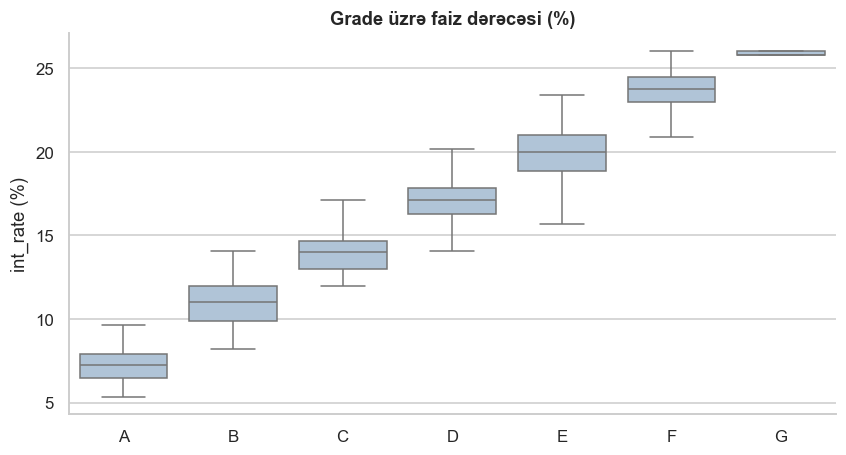

In [47]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=d, x="grade", y="int_rate", order=list("ABCDEFG"),
            color="#a9c4de", showfliers=False)
plt.title("Grade üzrə faiz dərəcəsi (%)")
plt.xlabel("")
plt.ylabel("int_rate (%)")
plt.show()

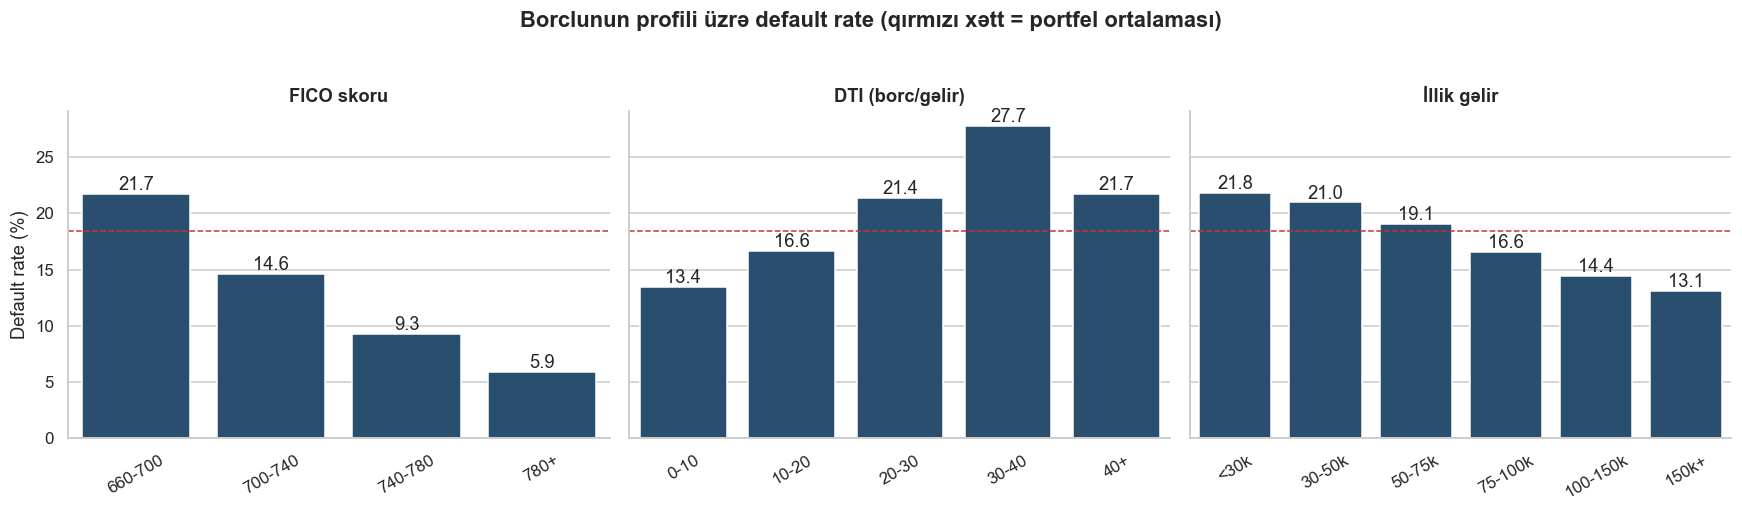

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for a, col, title in zip(ax, ["fico_band", "dti_band", "income_band"],
                         ["FICO skoru", "DTI (borc/gəlir)", "İllik gəlir"]):
    r = d.groupby(col, observed=True)["default"].mean() * 100
    sns.barplot(x=r.index.astype(str), y=r.values, color=BLUE, ax=a)
    a.bar_label(a.containers[0], fmt="%.1f")
    a.axhline(overall, color=RED, ls="--", lw=1)
    a.set_title(title)
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)

ax[0].set_ylabel("Default rate (%)")
plt.suptitle("Borclunun profili üzrə default rate (qırmızı xətt = portfel ortalaması)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

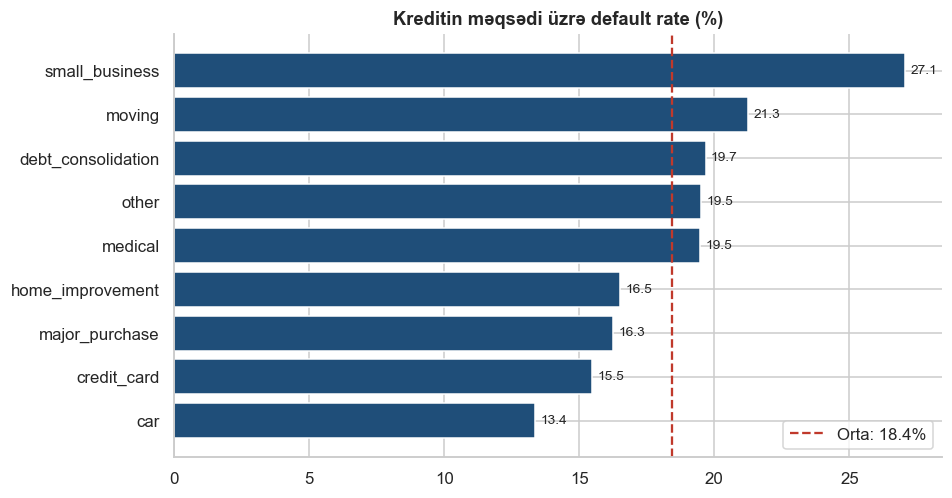

In [49]:
p = d.groupby("purpose").agg(loans=("id", "count"), rate=("default", "mean"))
p = p[p["loans"] >= 5000]
p["rate"] = p["rate"] * 100
p = p.sort_values("rate")

plt.figure(figsize=(9, 5))
plt.barh(p.index, p["rate"], color=BLUE)
plt.axvline(overall, color=RED, ls="--", label=f"Orta: {overall:.1f}%")
for i, v_ in enumerate(p["rate"]):
    plt.text(v_ + 0.2, i, f"{v_:.1f}", va="center", fontsize=9)
plt.title("Kreditin məqsədi üzrə default rate (%)")
plt.legend()
plt.show()

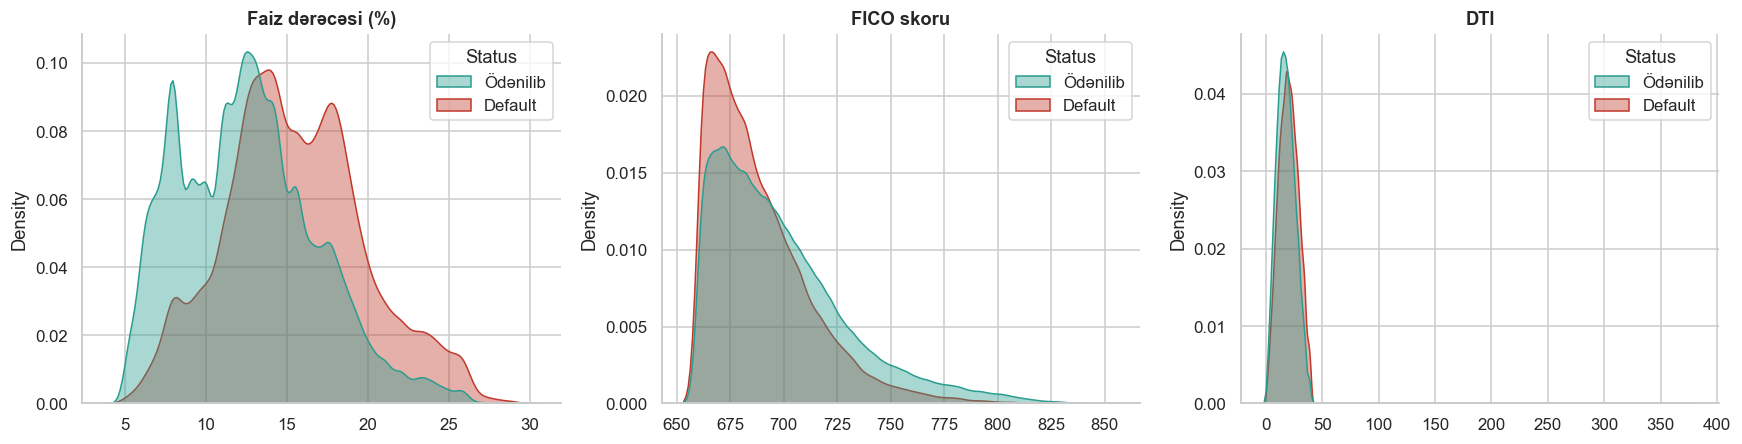

In [50]:
s = d.sample(200_000, random_state=42).copy()
s["Status"] = s["default"].map({0: "Ödənilib", 1: "Default"})

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, title in zip(ax, ["int_rate", "fico_avg", "dti"],
                         ["Faiz dərəcəsi (%)", "FICO skoru", "DTI"]):
    sns.kdeplot(data=s, x=col, hue="Status", common_norm=False, fill=True, alpha=0.4,
                palette={"Ödənilib": GREEN, "Default": RED}, ax=a)
    a.set_title(title)
    a.set_xlabel("")
plt.tight_layout()
plt.show()

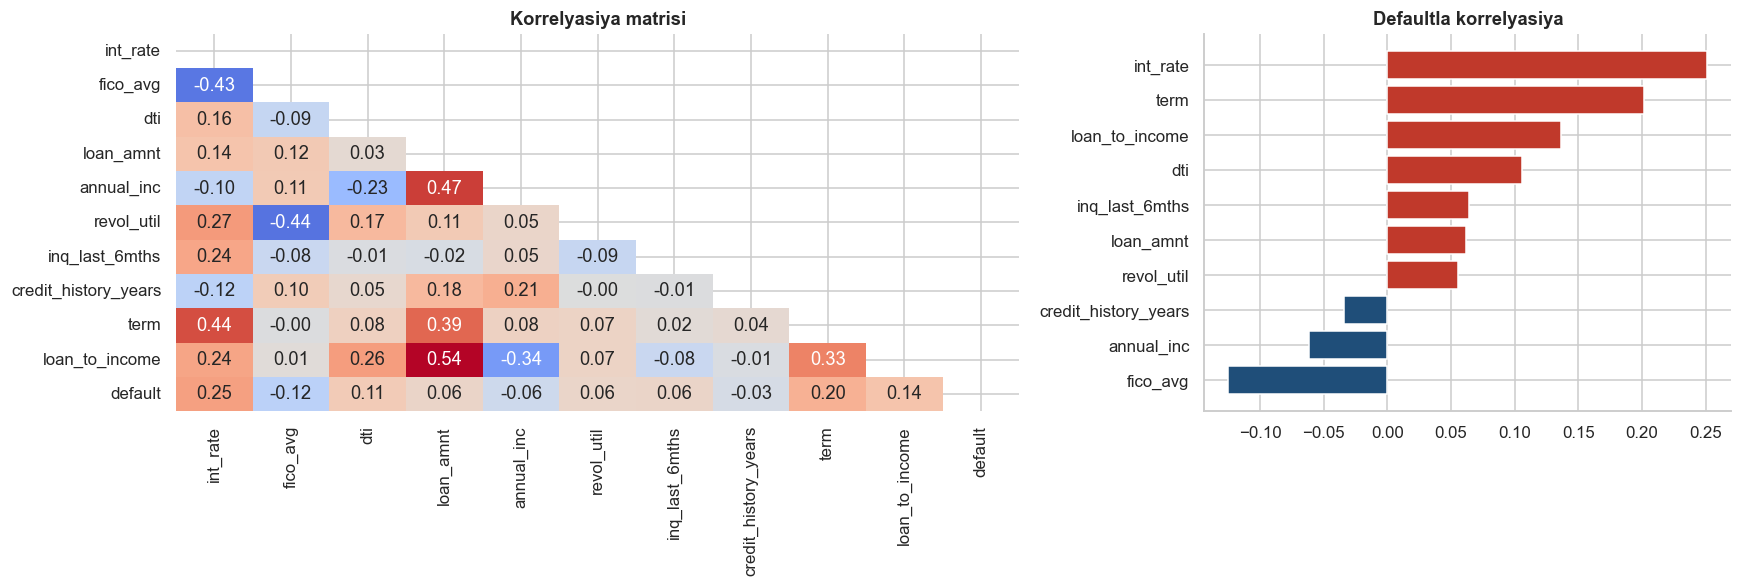

In [51]:
feats = ["int_rate", "fico_avg", "dti", "loan_amnt", "annual_inc", "revol_util",
         "inq_last_6mths", "credit_history_years", "term", "loan_to_income"]

corr = d[feats + ["default"]].corr()

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, cbar=False, ax=ax[0])
ax[0].set_title("Korrelyasiya matrisi")

c = corr["default"].drop("default").sort_values()
ax[1].barh(c.index, c.values, color=[RED if x > 0 else BLUE for x in c.values])
ax[1].set_title("Defaultla korrelyasiya")

plt.tight_layout()
plt.show()

In [53]:
a = d.groupby("grade").agg(loans=("id", "count"), volume=("loan_amnt", "sum"),
                           defaults=("default", "sum"), avg_int=("int_rate", "mean"),
                           profit=("profit", "sum"))
b = bad.groupby("grade").agg(unpaid=("unpaid_principal", "sum"),
                             recov=("recoveries", "sum"), EAD=("unpaid_principal", "mean"))

el = a.join(b)
el["PD"] = el["defaults"] / el["loans"] * 100
el["LGD"] = (1 - el["recov"] / el["unpaid"]) * 100
el["loss"] = el["unpaid"] - el["recov"]                     
el["EL_rate"] = el["loss"] / el["volume"] * 100
el["EL_share"] = el["loss"] / el["loss"].sum() * 100
el["vol_share"] = el["volume"] / el["volume"].sum() * 100
el["ROI"] = el["profit"] / el["volume"] * 100

el[["loans", "PD", "LGD", "EAD", "EL_rate", "EL_share", "ROI"]].round(2)

,loans,PD,LGD,EAD,EL_rate,EL_share,ROI
grade,,,,,,,
A,146132,5.57,87.57,6933.77,2.42,3.58,7.22
B,241173,12.04,87.81,7783.60,6.19,14.37,8.87
C,225142,20.37,87.67,9207.84,11.74,26.82,8.82
D,126175,28.13,87.69,10898.59,17.90,24.57,7.28
E,62022,36.75,87.59,13599.85,24.68,19.66,4.81
F,20777,42.30,87.20,15434.13,29.94,8.57,4.09
G,4938,46.60,87.12,16776.61,32.83,2.44,2.73


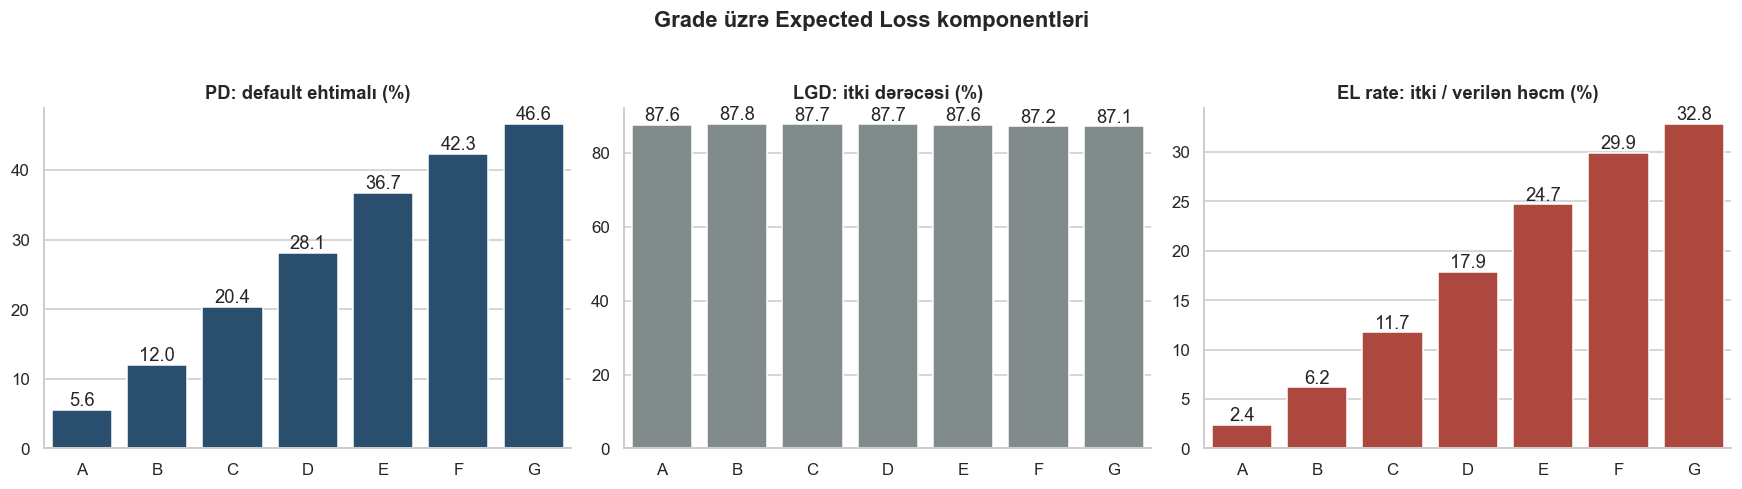

In [55]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))

for a_, col, title, color in zip(ax, ["PD", "LGD", "EL_rate"],
                                 ["PD: default ehtimalı (%)", "LGD: itki dərəcəsi (%)",
                                  "EL rate: itki / verilən həcm (%)"],
                                 [BLUE, GREY, RED]):
    sns.barplot(x=el.index, y=el[col], color=color, ax=a_)
    a_.bar_label(a_.containers[0], fmt="%.1f")
    a_.set_title(title)
    a_.set_xlabel("")
    a_.set_ylabel("")

plt.suptitle("Grade üzrə Expected Loss komponentləri", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

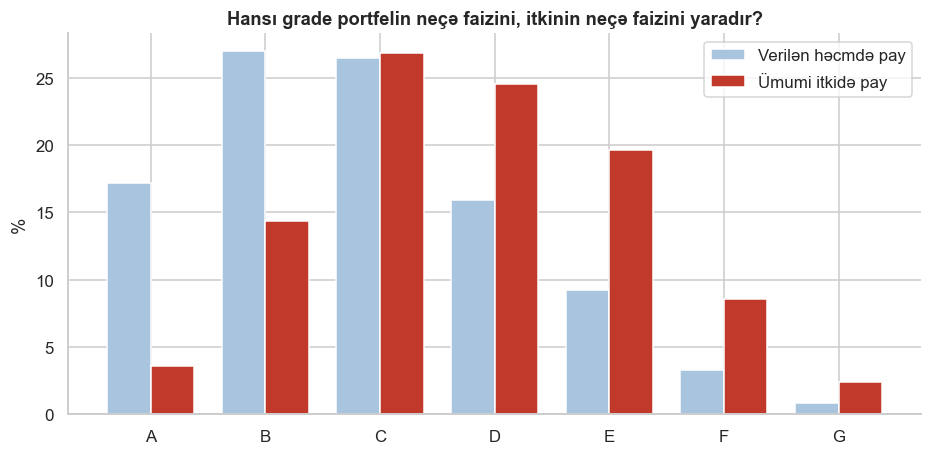

In [56]:
x = np.arange(len(el))
w = 0.38

plt.figure(figsize=(10, 4.5))
plt.bar(x - w/2, el["vol_share"], w, label="Verilən həcmdə pay", color="#a9c4de")
plt.bar(x + w/2, el["EL_share"], w, label="Ümumi itkidə pay", color=RED)
plt.xticks(x, el.index)
plt.ylabel("%")
plt.title("Hansı grade portfelin neçə faizini, itkinin neçə faizini yaradır?")
plt.legend()
plt.show()

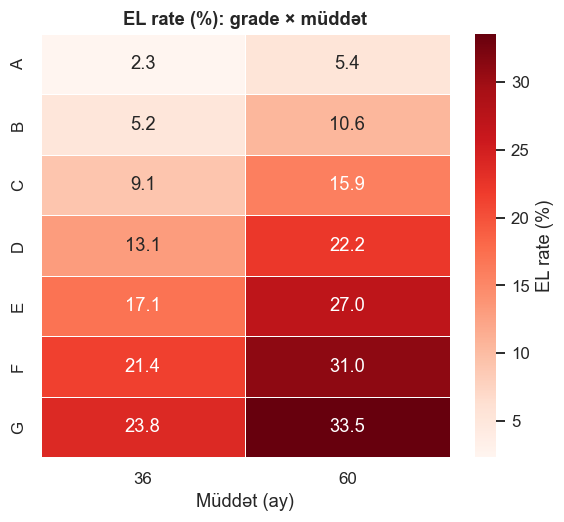

In [57]:
pl = d.pivot_table(index="grade", columns="term", values="loss", aggfunc="sum")
pv_ = d.pivot_table(index="grade", columns="term", values="loan_amnt", aggfunc="sum")
hm = pl / pv_ * 100

plt.figure(figsize=(6, 5))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5,
            cbar_kws={"label": "EL rate (%)"})
plt.title("EL rate (%): grade × müddət")
plt.xlabel("Müddət (ay)")
plt.ylabel("")
plt.show()

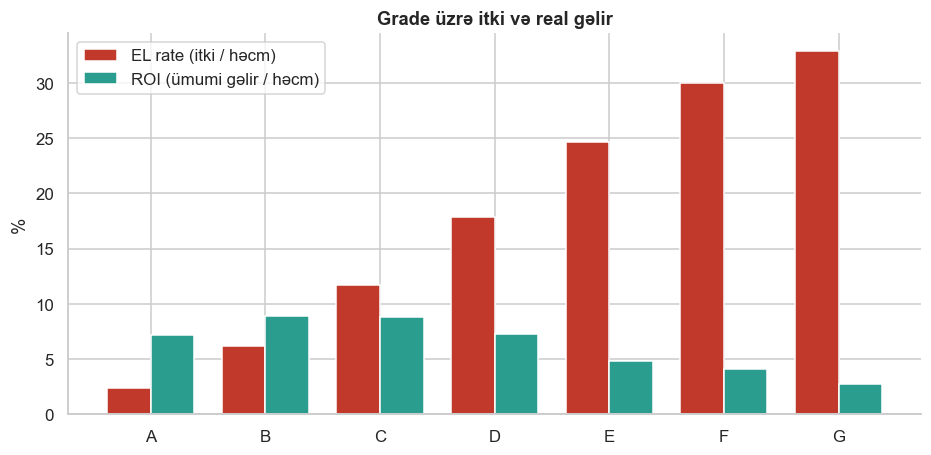

In [58]:
x = np.arange(len(el))
w = 0.38

plt.figure(figsize=(10, 4.5))
plt.bar(x - w/2, el["EL_rate"], w, label="EL rate (itki / həcm)", color=RED)
plt.bar(x + w/2, el["ROI"], w, label="ROI (ümumi gəlir / həcm)", color=GREEN)
plt.axhline(0, color="black", lw=0.8)
plt.xticks(x, el.index)
plt.ylabel("%")
plt.title("Grade üzrə itki və real gəlir")
plt.legend()
plt.show()

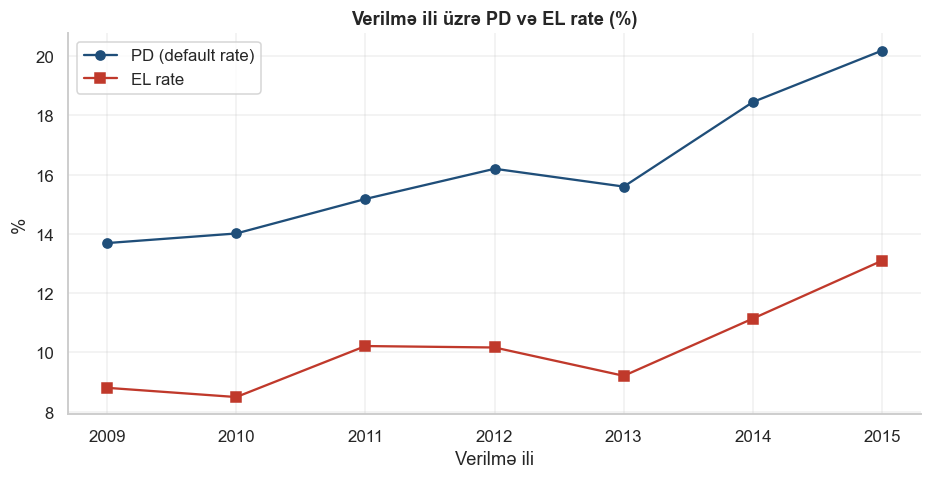

In [59]:
yv = d.groupby("issue_year").agg(volume=("loan_amnt", "sum"), loss=("loss", "sum"),
                                 pd_=("default", "mean"))
yv["EL_rate"] = yv["loss"] / yv["volume"] * 100
yv["pd_"] = yv["pd_"] * 100

plt.figure(figsize=(10, 4.5))
plt.plot(yv.index, yv["pd_"], marker="o", color=BLUE, label="PD (default rate)")
plt.plot(yv.index, yv["EL_rate"], marker="s", color=RED, label="EL rate")
plt.title("Verilmə ili üzrə PD və EL rate (%)")
plt.xlabel("Verilmə ili")
plt.ylabel("%")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

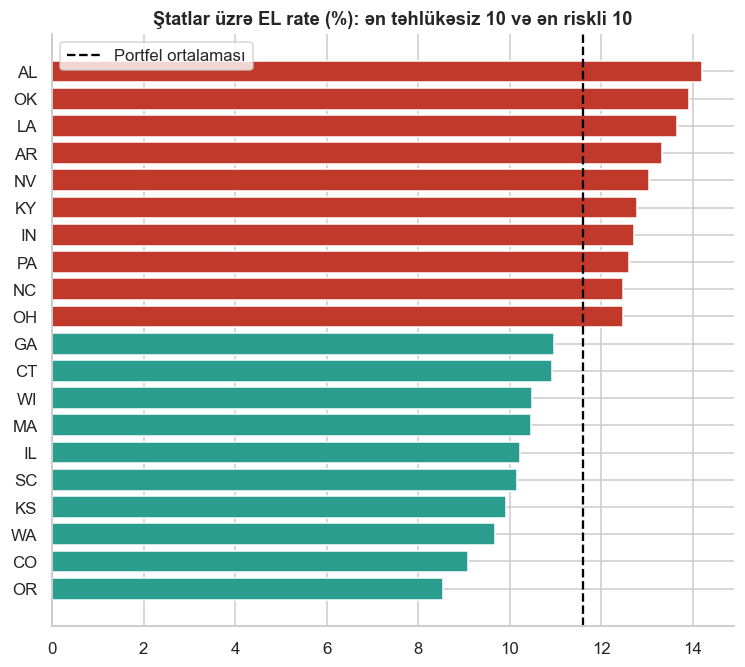

In [60]:
st = d.groupby("addr_state").agg(loans=("id", "count"), volume=("loan_amnt", "sum"),
                                 loss=("loss", "sum"))
st = st[st["loans"] >= 5000].copy()
st["EL_rate"] = st["loss"] / st["volume"] * 100
st = st.sort_values("EL_rate")
top = pd.concat([st.head(10), st.tail(10)])

plt.figure(figsize=(8, 7))
plt.barh(top.index, top["EL_rate"], color=[GREEN] * 10 + [RED] * 10)
plt.axvline(d["loss"].sum() / d["loan_amnt"].sum() * 100, color="black", ls="--", label="Portfel ortalaması")
plt.title("Ştatlar üzrə EL rate (%): ən təhlükəsiz 10 və ən riskli 10")
plt.legend()
plt.show()

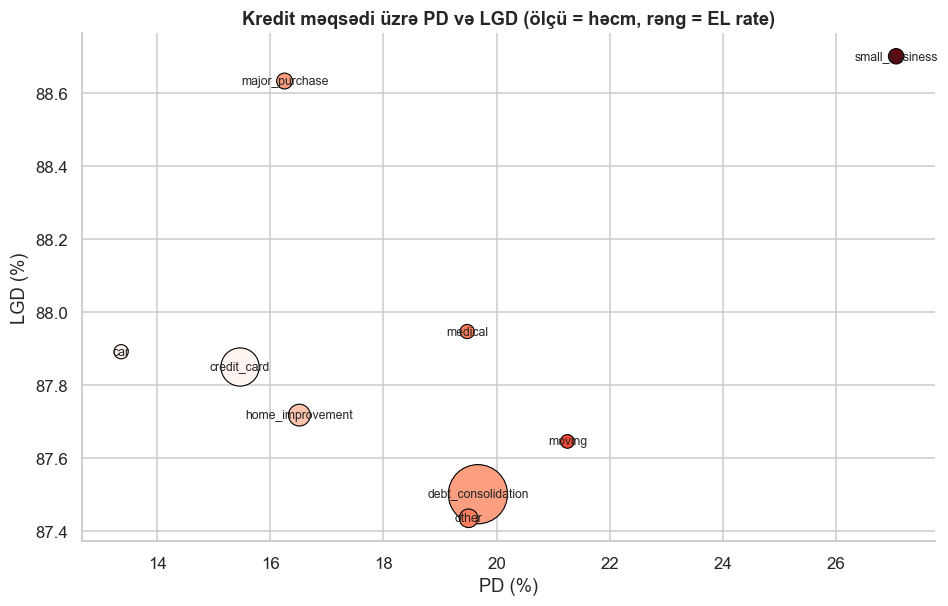

In [61]:
pa = d.groupby("purpose").agg(loans=("id", "count"), volume=("loan_amnt", "sum"),
                              defaults=("default", "sum"), loss=("loss", "sum"))
pb = bad.groupby("purpose").agg(unpaid=("unpaid_principal", "sum"), recov=("recoveries", "sum"))

pp = pa.join(pb)
pp = pp[pp["loans"] >= 5000].copy()
pp["PD"] = pp["defaults"] / pp["loans"] * 100
pp["LGD"] = (1 - pp["recov"] / pp["unpaid"]) * 100
pp["EL_rate"] = pp["loss"] / pp["volume"] * 100
pp["volume_m"] = pp["volume"] / 1e6

plt.figure(figsize=(10, 6))
sns.scatterplot(data=pp, x="PD", y="LGD", size="volume_m", hue="EL_rate",
                sizes=(80, 1500), palette="Reds", legend=False, edgecolor="black")
for name, r in pp.iterrows():
    plt.text(r["PD"], r["LGD"], name, fontsize=8, ha="center", va="center")
plt.title("Kredit məqsədi üzrə PD və LGD (ölçü = həcm, rəng = EL rate)")
plt.xlabel("PD (%)")
plt.ylabel("LGD (%)")
plt.show()

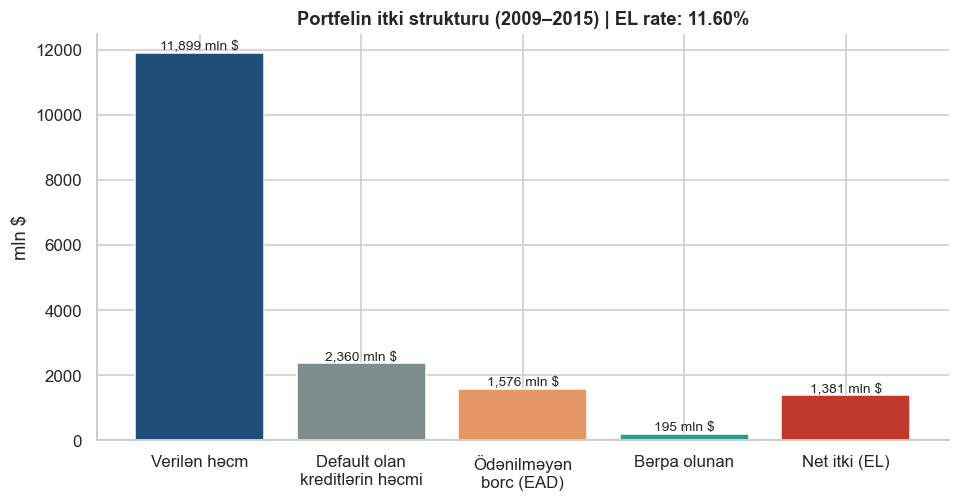

In [62]:
vol = d["loan_amnt"].sum() / 1e6
def_vol = bad["loan_amnt"].sum() / 1e6
ead = bad["unpaid_principal"].sum() / 1e6
rec = bad["recoveries"].sum() / 1e6
net = ead - rec

labels = ["Verilən həcm", "Default olan\nkreditlərin həcmi", "Ödənilməyən\nborc (EAD)",
          "Bərpa olunan", "Net itki (EL)"]
values = [vol, def_vol, ead, rec, net]
colors = [BLUE, GREY, "#e59866", GREEN, RED]

plt.figure(figsize=(10, 4.8))
plt.bar(labels, values, color=colors)
for i, v_ in enumerate(values):
    plt.text(i, v_, f"{v_:,.0f} mln $", ha="center", va="bottom", fontsize=9)
plt.title(f"Portfelin itki strukturu (2009–2015) | EL rate: {net / vol * 100:.2f}%")
plt.ylabel("mln $")
plt.show()

In [63]:
export = df.copy()

band_cols = ["income_band", "dti_band", "fico_band", "loan_band",
             "rate_band", "history_band", "revol_band", "inq_band"]
export = export.drop(columns=[c for c in band_cols if c in export.columns])

export = export.rename(columns={"default": "is_default"})

export["unpaid_principal"] = (export["loan_amnt"] - export["total_rec_prncp"]).clip(lower=0)   # EAD
export["net_loss"] = np.where(
    export["is_default"] == 1,
    (export["unpaid_principal"] - export["recoveries"]).clip(lower=0),
    0,
)
export["profit"] = export["total_pymnt"] - export["loan_amnt"]

export["issue_d"] = export["issue_d"].dt.strftime("%Y-%m-%d")
export["earliest_cr_line"] = export["earliest_cr_line"].dt.strftime("%Y-%m-%d")

float_cols = export.select_dtypes(include="float").columns
export[float_cols] = export[float_cols].round(4)

In [64]:
export.to_csv("lc_clean.csv", index=False, encoding="utf-8")